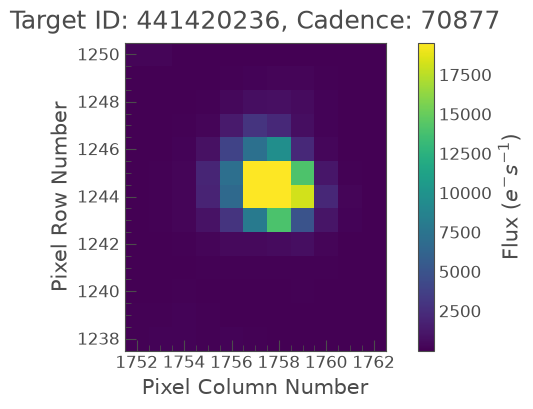

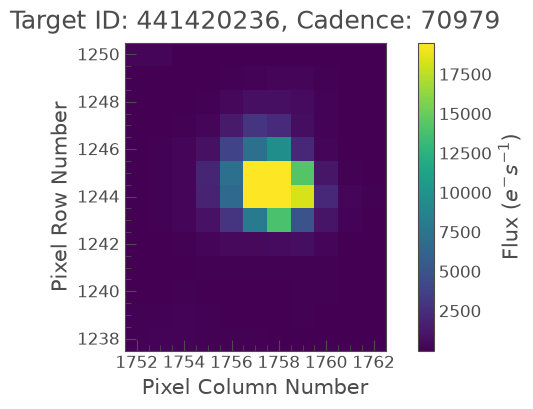

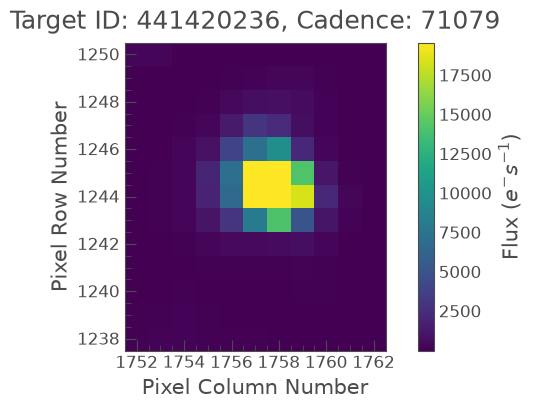

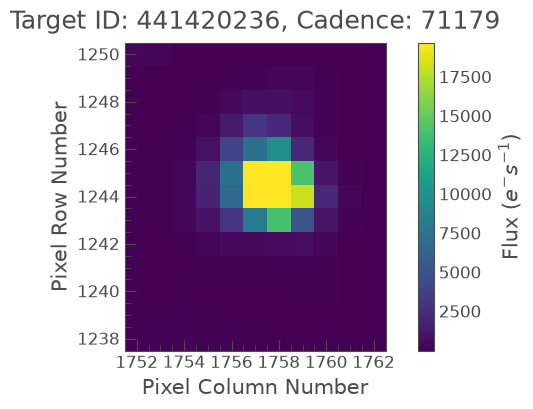

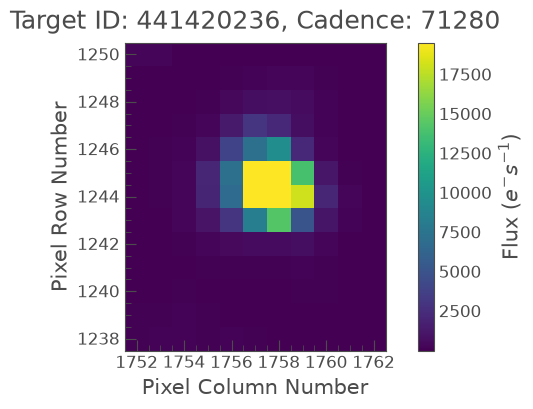

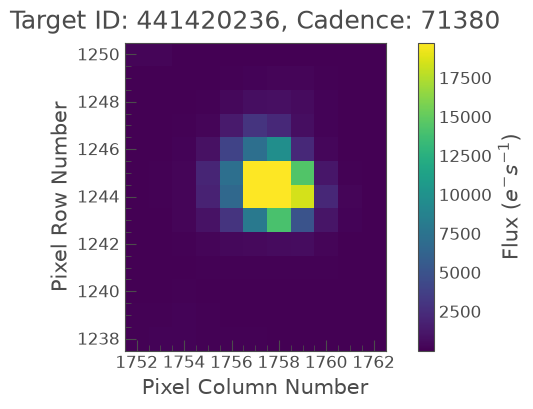

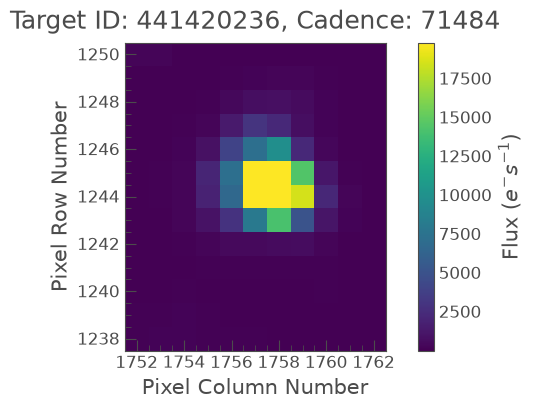

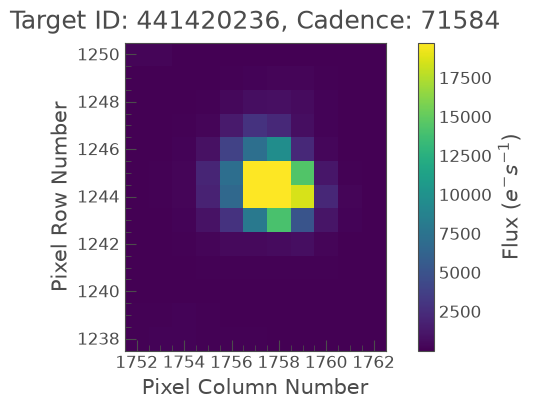

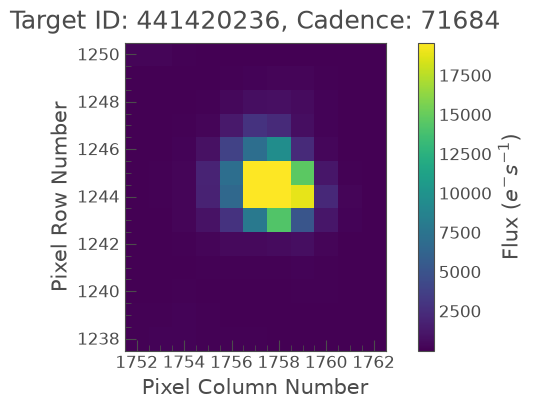

In [26]:
%matplotlib inline
import lightkurve as lk
import matplotlib.pyplot as plt

search_result = lk.search_targetpixelfile("AU Mic", mission="TESS", sector=1, author="SPOC")
tpf = search_result.download()

for i in range(0, 9):
    tpf.plot(frame=i*100)

plt.show()


In [ ]:
import pandas as pd
import numpy as np

lc = tpf.to_lightcurve(aperture_mask=tpf.pipeline_mask)

clean_mask = ~np.isnan(lc.flux.value) & ~np.isnan(lc.time.value)
times = lc.time.value[clean_mask]
fluxes = lc.flux.value[clean_mask]

dataset = pd.DataFrame({
    'Time_Days': times,
    'Brightness_Flux': fluxes
})

print(dataset.head(10))

dataset.to_csv("pi_mensae_dataset.csv", index=False)


     Time_Days  Brightness_Flux
0  1325.901401     273568.96875
1  1325.902790     273536.06250
2  1325.904179     273568.31250
3  1325.905568     273537.03125
4  1325.906957     273578.84375
5  1325.908346     273690.09375
6  1325.909735     273604.81250
7  1325.911124     273595.78125
8  1325.912513     273592.84375
9  1325.913901     273697.12500


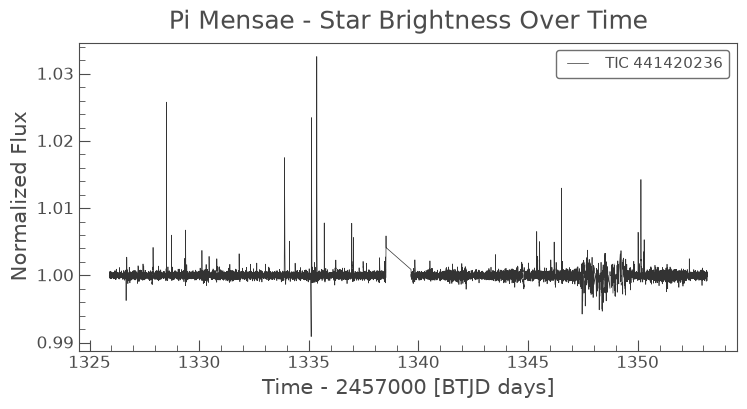

In [28]:
# 1. Flatten the light curve to remove long-term telescope drift waves
flat_lc = lc.flatten()

# 2. Plot the standard light curve over time
flat_lc.plot(title="Pi Mensae - Star Brightness Over Time")
plt.show()


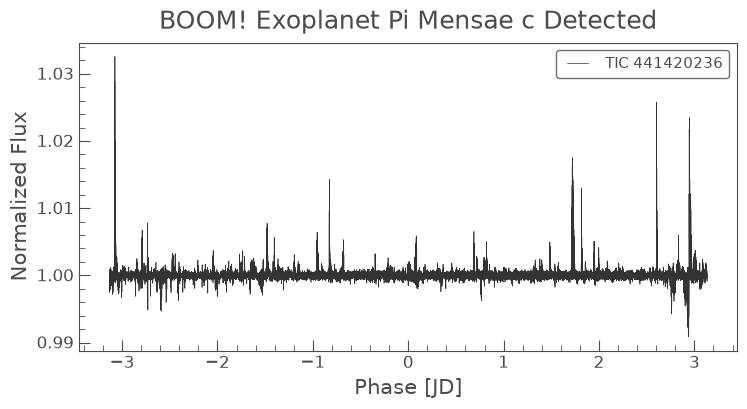

In [29]:
# Fold the data using the planet's known orbital period (6.268 days)
folded_lc = flat_lc.fold(period=6.268)

# Plot it!
folded_lc.plot(title="BOOM! Exoplanet Pi Mensae c Detected")
plt.show()
